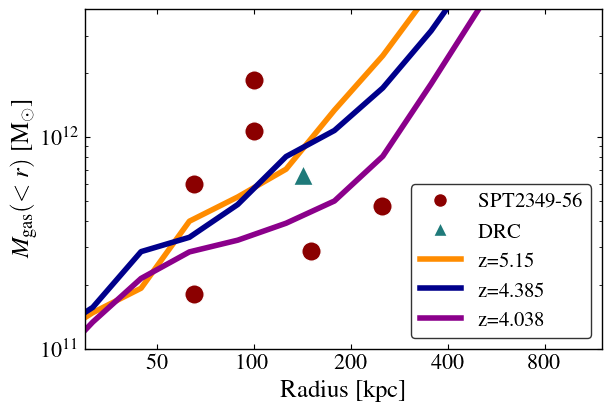

In [46]:
"""
Cold gas mass vs. radius for the observed z~4 protoclusters SPT2349-56 and the
Distant Red Core (DRC).

Radius = half of the quoted region diameter (DRC: geometric-mean radius of the
260x310 kpc region). Dotted lines are loci of constant mean gas density for a
sphere, M = (4/3) pi rho r^3.

"""

import numpy as np
import matplotlib.pyplot as plt
import h5py
from set_style import set_style

# ------------------------------------------------------------------
# Literature data: (label, radius [kpc], M_gas [Msun], reference key, flags)
# ------------------------------------------------------------------
# lower=True -> value is a lower limit (arrow pointing up)

spt = [
    # label,                         r_kpc, M_gas,   ref,        lower
    ("Miller+18 (CO(4-3)/[CII])",     65.0, 6.0e11, "Miller18", False),
    ("Miller+18 (CO(2-1))",           65.0, 1.8e11, "Miller18", False),
    ("Hill+20 core",                 150.0, 2.9e11, "Hill20",   False),
    ("Hill+20 core + north",         250.0, 4.7e11, "Hill20",   False),
    ("Zhou+25 ALMA (CO(4-3))",       100.0, 1.06e12, "Zhou25",  False),
    ("Zhou+25 ACA (CO(4-3))",        100.0, 1.86e12, "Zhou25",  True),
]
drc = [
    ("Oteo+18 ([CI](1-0))", np.sqrt(130.0 * 155.0), 6.6e11, "Oteo18", True),
]

# Simulated object (leave empty to skip). Example: SIM = [(r_kpc, Mgas_Msun), ...]
SIM = []

# Marker per reference (secondary encoding, so identity is not colour-only)
style = {
    "Miller18": dict(marker="o", ms=14),
    "Hill20":   dict(marker="o", ms=14),
    "Zhou25":   dict(marker="o", ms=14),
    "Oteo18":   dict(marker="^", ms=14),
}
color_spt = "darkred"   # SPT2349-56
color_drc = "#1F7A7A"   # DRC
color_sim = "#222222"

set_style('mnras')

fig, ax = plt.subplots(figsize=(6, 4))

fs = 17

def draw(points, color):
    for lab, r, m, ref, lower in points:
        st = style[ref]
        #if lower:
            
            #ax.errorbar(r, m, yerr=0.18 * m, lolims=True, fmt="none",
             #           color=color, ecolor=color, elinewidth=2.4, capsize=5, zorder=3)
        ax.plot(r, m, ls="none", marker=st["marker"], ms=st["ms"],
                mfc=color, mec="white", mew=1.0, zorder=4)


draw(spt, color_spt)
draw(drc, color_drc)

if SIM:
    sr, sm = np.array(SIM).T
    ax.plot(sr, sm, "-", color=color_sim, lw=2.0, zorder=5)
    ax.text(sr[-1], sm[-1], "  Cluster129", color=color_sim, fontsize=fs,
            va="center")

# --- direct labels (text in ink colour, not series colour) --------
#ax.text(58, 1.3e12, "SPT2349-56", color="0.15", fontsize=fs-2, fontweight="bold",
#        ha="left", va="center")
#ax.text(158, 7e11, "DRC", color="0.15", fontsize=fs-2, fontweight="bold",
#        ha="left", va="center")

# --- legend: reference = marker shape, object = colour -----------
from matplotlib.lines import Line2D
handles = [
    #Line2D([], [], ls="none", marker="o", ms=8, mfc="0.5", mec="white",
           #label="Miller+18"),
    #Line2D([], [], ls="none", marker="s", ms=8, mfc="0.5", mec="white",
           #label="Hill+20"),
    #Line2D([], [], ls="none", marker="D", ms=8, mfc="0.5", mec="white",
           #label="Zhou+25"),
    #Line2D([], [], ls="none", marker="^", ms=9, mfc="0.5", mec="white",
           #label="Oteo+18"),
    Line2D([], [], ls="none", marker="o", ms=10, mfc=color_spt, mec="white",
           label="SPT2349-56"),
    Line2D([], [], ls="none", marker="^", ms=10, mfc=color_drc, mec="white",
           label="DRC"),
]
      
#ax.set_title('Cumulative cold gas', fontsize=fs+1)  
ax.set_xscale("log")
ax.set_yscale("log")
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
ax.set_xlim(30, 1200)
ax.xaxis.set_major_locator(FixedLocator([50, 100, 200, 400, 800]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_ylim(1e11, 4e12)
ax.set_xlabel("Radius [kpc]", fontsize=fs+1)
ax.set_ylabel(r"$M_{\rm gas}(<r)$ [M$_\odot$]", fontsize=fs+1)
#ax.grid(True, which="major", color="0.9", lw=0.8, zorder=0)
ax.tick_params(which="both", direction="in", top=True, right=True, labelsize=fs-1)


with h5py.File('Mgas_sfr_radius_129.hdf5','r') as f:

    z = ['5.15','5.017','4.385','4.038', '3.7']
    colors = ['darkorange', 'darkgreen','darkblue', 'darkmagenta', 'crimson' ]
    snaps = [46,47,52,55]
    
    keys = list(f.keys())
    for i,k in enumerate(snaps):
        if i != 1:
            radius, mgas = f[f'snap_{k:03d}/radius'][()], f[f'snap_{k:03d}/Mcoldgas'][()]
            ax.plot(radius, mgas, ls='-', lw=4, color=colors[i], label='z='+z[i])
    
#ax.legend(loc="lower right", bbox_to_anchor=(1.02, 1), borderaxespad=0, fontsize=fs-1, frameon=False)        
handles2, labels = ax.get_legend_handles_labels()
#ax.legend(handles=handles+handles2, loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0, fontsize=fs-1, frameon=False)
ax.legend(handles=handles+handles2, loc="lower right", fontsize=fs-2, frameon=True)

plt.savefig("plots/mgas_vs_radius.png", dpi=200,bbox_inches="tight" )

plt.show()